# Qualify: sleep quality prediction

## 1. Data Loading and Cleaning

### Library Imports

In [1]:
# General libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Data splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Regression models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Evaluation metrics
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

### Loading Dataset

In [2]:
# Project paths
RAW = "../data/raw"
OUT = "../data/processed"
FIG = "../figures"
RES = "../results"

for folder in [OUT, FIG, RES]:
    os.makedirs(folder, exist_ok=True)


RANDOM_STATE = 42

TARGET = "quality_of_sleep"
CLASS = "sleep_quality_class"
CLASS_ORDER = ["low", "medium", "high"]


NUM_FEATURES = [
    "age", "daily_steps", "heart_rate",
    "physical_activity_level", "sleep_duration", "stress_level"
]

CAT_FEATURES = ["gender", "bmi_category"]

FEATURES = [
    "age", "gender", "bmi_category", "daily_steps",
    "heart_rate", "physical_activity_level",
    "sleep_duration", "stress_level"
]

In [3]:
df = pd.read_csv(
    f"{RAW}/Sleep_health_and_lifestyle_dataset.csv",
    keep_default_na=False,
    na_values=[""]
)

print("Original shape:", df.shape)

Original shape: (374, 13)


### Data Cleaning

In [4]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^\w]+", "_", regex=True)
    .str.strip("_")
)

# Standardize categorical text
for col in df.select_dtypes(include=["object", "str"]).columns:
    df[col] = df[col].str.strip().str.lower()

# Make BMI categories consistent
df["bmi_category"] = df["bmi_category"].replace({
    "normal weight": "normal"
})

print("Columns:", df.columns.tolist())

Columns: ['person_id', 'gender', 'age', 'occupation', 'sleep_duration', 'quality_of_sleep', 'physical_activity_level', 'stress_level', 'bmi_category', 'blood_pressure', 'heart_rate', 'daily_steps', 'sleep_disorder']


In [5]:
df = df.drop(columns=["person_id"])
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print(df.head())

Shape after removing duplicates: (132, 12)
  gender  age            occupation  sleep_duration  quality_of_sleep  \
0   male   27     software engineer             6.1                 6   
1   male   28                doctor             6.2                 6   
2   male   28  sales representative             5.9                 4   
3   male   28     software engineer             5.9                 4   
4   male   29               teacher             6.3                 6   

   physical_activity_level  stress_level bmi_category blood_pressure  \
0                       42             6   overweight         126/83   
1                       60             8       normal         125/80   
2                       30             8        obese         140/90   
3                       30             8        obese         140/90   
4                       40             7        obese         140/90   

   heart_rate  daily_steps sleep_disorder  
0          77         4200           none

In [6]:
print("Missing values:\n", df.isna().sum())

df = df.dropna(subset=[TARGET]).copy()

invalid = (
    (df["age"] < 18) |
    (df["heart_rate"] > 120) |
    (df["sleep_duration"] > 12)
)

print("Invalid rows:", invalid.sum())

df = df.loc[~invalid].reset_index(drop=True)

print("Final shape:", df.shape)

Missing values:
 gender                     0
age                        0
occupation                 0
sleep_duration             0
quality_of_sleep           0
physical_activity_level    0
stress_level               0
bmi_category               0
blood_pressure             0
heart_rate                 0
daily_steps                0
sleep_disorder             0
dtype: int64
Invalid rows: 0
Final shape: (132, 12)


In [7]:
df[CLASS] = pd.cut(
    df[TARGET],
    bins=[-np.inf, 6, 8, np.inf],
    labels=CLASS_ORDER,
    right=False
).astype(str)

print(df[TARGET].describe())
print("\nClass counts:")
print(df[CLASS].value_counts().reindex(CLASS_ORDER))

count    132.000000
mean       7.151515
std        1.269037
min        4.000000
25%        6.000000
50%        7.000000
75%        8.000000
max        9.000000
Name: quality_of_sleep, dtype: float64

Class counts:
sleep_quality_class
low       10
medium    65
high      57
Name: count, dtype: int64


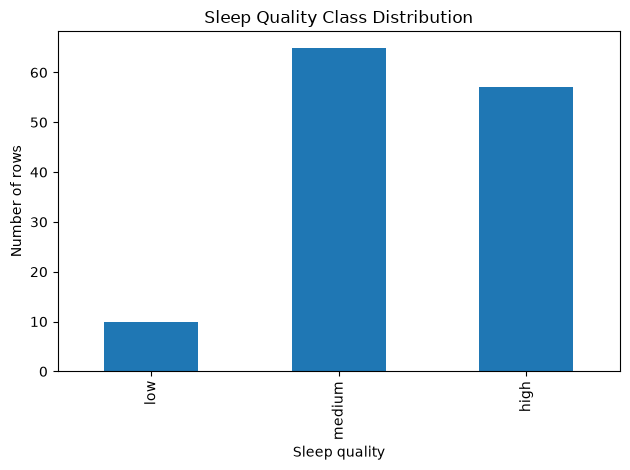

In [8]:
df[CLASS].value_counts().reindex(CLASS_ORDER).plot(kind="bar")

plt.title("Sleep Quality Class Distribution")
plt.xlabel("Sleep quality")
plt.ylabel("Number of rows")
plt.tight_layout()
plt.savefig(f"{FIG}/label_distribution.png", dpi=150)
plt.show()

## 2.1 Exploratory Data Analysis (EDA)

1. Dataset Overview

- Load cleaned file
- Display its shape, column name, dtype

2. Summary Statistics

- Summarize numeric features e.g. sleep duration, stress levels, physical activity such as daily steps taken
- Use the results to interpret and draw conclusions about the range and identify possible anomaly or unusal outliers

3. Sleep Quality Classes
- Count how many records are classified as low,medium, and high quality
- A bar chart will be used to visualize frequency in each category

4. Visualizing Feature Distributions

5. Correlation Heatmap

6. Assessing Sleep Quality against other features

In [9]:
sns.set_style("whitegrid")

labels = {
    "age": "Age (years)",
    "daily_steps": "Daily steps",
    "heart_rate": "Resting heart rate (bpm)",
    "physical_activity_level": "Physical activity (min/day)",
    "sleep_duration": "Sleep duration (hours)",
    "stress_level": "Stress level (1-10)",
    "quality_of_sleep": "Sleep quality (1-10)",
    "gender_male": "Gender (male = 1)",
    "bmi_order": "BMI category (ordered)"
}

class_order = CLASS_ORDER
class_colors = ["#d9534f", "#f0ad4e", "#5cb85c"]
num_cols = NUM_FEATURES

1. Dataset Overview

In [10]:
print("Shape:", df.shape)
df.head()

Shape: (132, 13)


,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder,sleep_quality_class
0,male,27,software engineer,6.1,6,42,6,overweight,126/83,77,4200,none,medium
1,male,28,doctor,6.2,6,60,8,normal,125/80,75,10000,none,medium
2,male,28,sales representative,5.9,4,30,8,obese,140/90,85,3000,sleep apnea,low
3,male,28,software engineer,5.9,4,30,8,obese,140/90,85,3000,insomnia,low
4,male,29,teacher,6.3,6,40,7,obese,140/90,82,3500,insomnia,medium


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   gender                   132 non-null    str    
 1   age                      132 non-null    int64  
 2   occupation               132 non-null    str    
 3   sleep_duration           132 non-null    float64
 4   quality_of_sleep         132 non-null    int64  
 5   physical_activity_level  132 non-null    int64  
 6   stress_level             132 non-null    int64  
 7   bmi_category             132 non-null    str    
 8   blood_pressure           132 non-null    str    
 9   heart_rate               132 non-null    int64  
 10  daily_steps              132 non-null    int64  
 11  sleep_disorder           132 non-null    str    
 12  sleep_quality_class      132 non-null    str    
dtypes: float64(1), int64(6), str(6)
memory usage: 13.5 KB


In [12]:
print("Missing values per column:")
print(df.isna().sum())

Missing values per column:
gender                     0
age                        0
occupation                 0
sleep_duration             0
quality_of_sleep           0
physical_activity_level    0
stress_level               0
bmi_category               0
blood_pressure             0
heart_rate                 0
daily_steps                0
sleep_disorder             0
sleep_quality_class        0
dtype: int64


Based on the output results, the clean and processed dataset contains 2091 rows. Only stress_level feature has missing values, namely 63 rows, which contributes to approximately 3%. The missing rows in both the raw versions of the dataset were filled with the training median when building the model.

2. Generating Summary Statistics

In [13]:
df[num_cols +[TARGET]].describe().round(2)

,age,daily_steps,heart_rate,physical_activity_level,sleep_duration,stress_level,quality_of_sleep
count,132.00,132.00,132.00,132.00,132.00,132.00,132.00
mean,41.13,6637.88,71.20,58.39,7.08,5.54,7.15
std,8.81,1766.29,4.87,20.47,0.78,1.74,1.27
min,27.00,3000.00,65.00,30.00,5.80,3.00,4.00
25%,33.75,5000.00,68.00,44.25,6.40,4.00,6.00
50%,41.00,7000.00,70.00,60.00,7.15,6.00,7.00
75%,49.00,8000.00,74.00,75.00,7.72,7.00,8.00
max,59.00,10000.00,86.00,90.00,8.50,8.00,9.00


In [14]:
# Count outliers with the IQR rule (more than 1.5 * IQR outside the quartiles)
for col in num_cols + [TARGET]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(col, ":", len(outliers), "outliers")

age : 0 outliers
daily_steps : 0 outliers
heart_rate : 5 outliers
physical_activity_level : 0 outliers
sleep_duration : 0 outliers
stress_level : 0 outliers
quality_of_sleep : 0 outliers


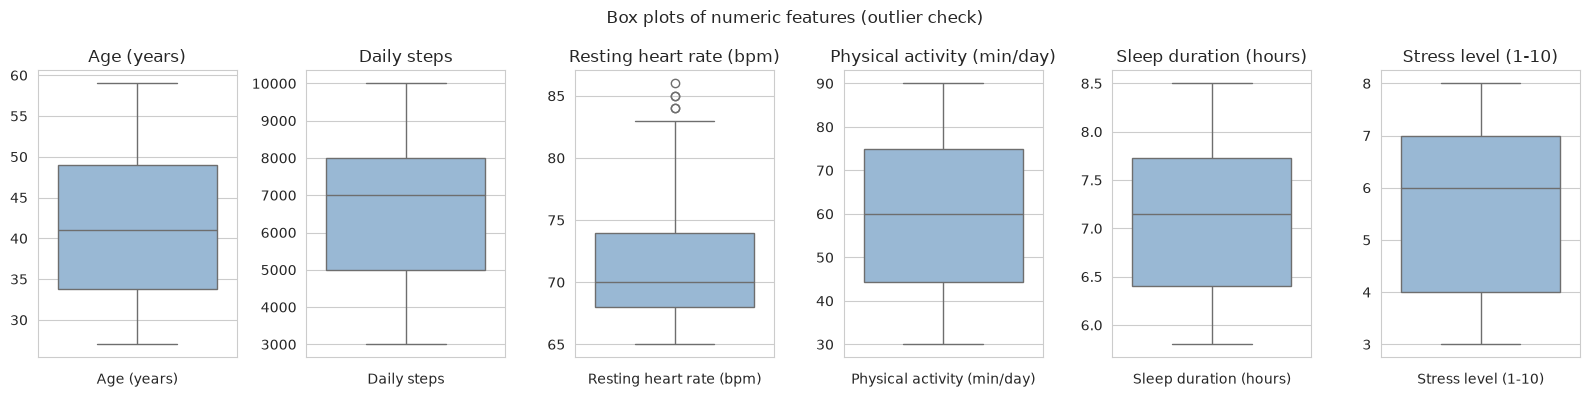

In [15]:
fig, axes = plt.subplots(1, 6, figsize=(16, 4))
for i in range(6):
    col = num_cols[i]
    sns.boxplot(y=df[col], ax=axes[i], color="#8fb8de")
    axes[i].set_title(labels[col])
    axes[i].set_xlabel(labels[col])
    axes[i].set_ylabel("")
plt.suptitle("Box plots of numeric features (outlier check)")
plt.tight_layout()
plt.savefig(FIG + "/eda_01_boxplots_outliers.png")
plt.show()

3. Sleep Quality Classes

In [16]:
counts = df[CLASS].value_counts()[class_order]
percent = (counts / len(df) * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": percent}))

                     count  percent
sleep_quality_class                
low                     10      7.6
medium                  65     49.2
high                    57     43.2


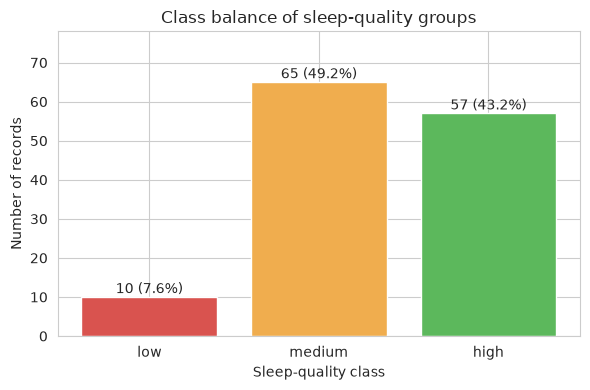

In [17]:
plt.figure(figsize=(6, 4))
plt.bar(class_order, counts, color=class_colors)
for i in range(3):
    plt.text(i, counts.iloc[i] + 1, str(counts.iloc[i]) + " (" + str(percent.iloc[i]) + "%)", ha="center")
plt.title("Class balance of sleep-quality groups")
plt.xlabel("Sleep-quality class")
plt.ylabel("Number of records")
plt.ylim(0, max(counts) * 1.2)
plt.tight_layout()
plt.savefig(FIG + "/eda_02_class_balance.png")
plt.show()

4. Visualizing Feature Distributions

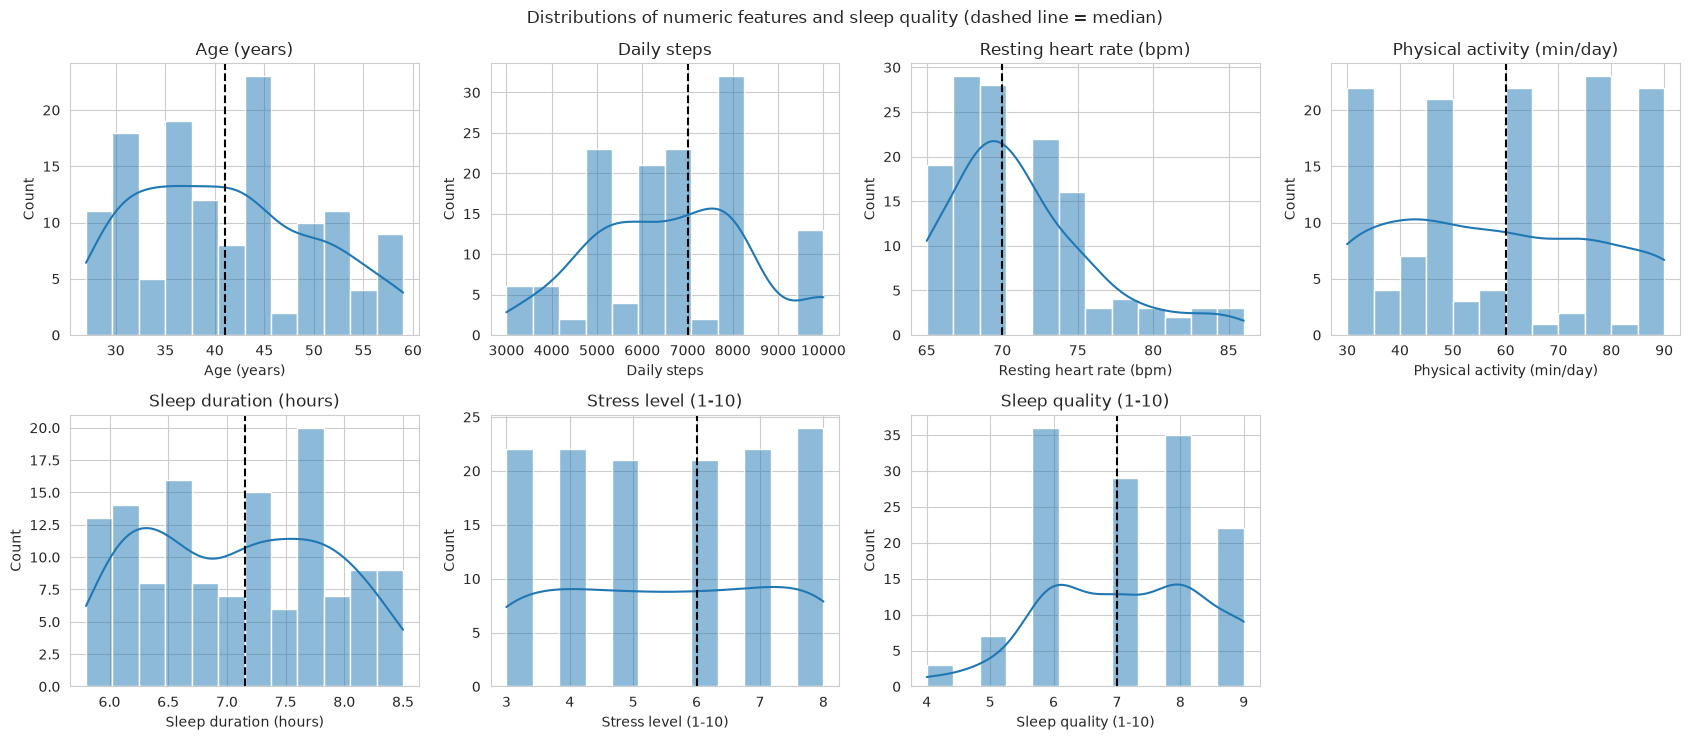

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
axes = axes.flatten()
for i in range(7):
    col = (num_cols + [TARGET])[i]
    sns.histplot(df[col], bins=12, kde=True, ax=axes[i])
    axes[i].axvline(df[col].median(), color="black", linestyle="--")
    axes[i].set_title(labels[col])
    axes[i].set_xlabel(labels[col])
    axes[i].set_ylabel("Count")
axes[7].axis("off")
plt.suptitle("Distributions of numeric features and sleep quality (dashed line = median)")
plt.tight_layout()
plt.savefig(FIG + "/eda_03_numeric_distributions.png")
plt.show()

Figure: The output demonstrates a set of histograms representing numeric features and sleep quality score. The dashed line intersecting the distribution indicates the median. The mean score of sleep quality is approximately 7.04

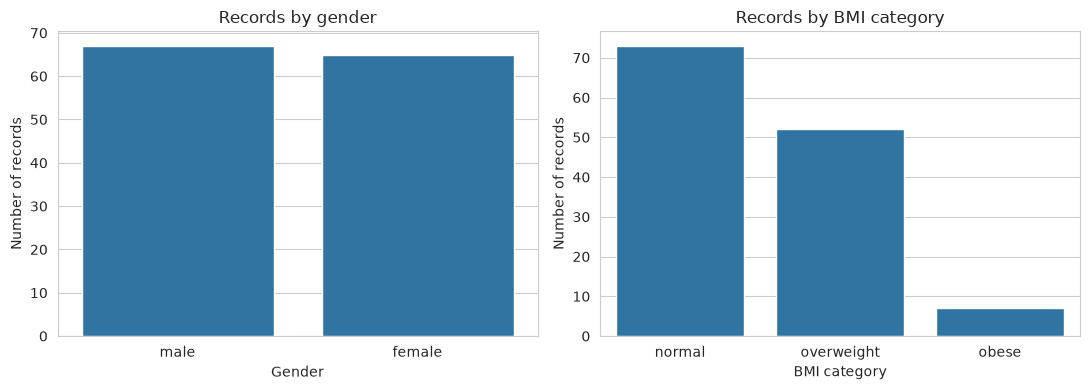

gender
male      67
female    65
Name: count, dtype: int64
bmi_category
normal        73
overweight    52
obese          7
Name: count, dtype: int64


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="gender", data=df, ax=axes[0])
axes[0].set_title("Records by gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of records")
sns.countplot(x="bmi_category", data=df, ax=axes[1], order=["normal", "overweight", "obese"])
axes[1].set_title("Records by BMI category")
axes[1].set_xlabel("BMI category")
axes[1].set_ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIG + "/eda_04_categorical_counts.png")
plt.show()
print(df["gender"].value_counts())
print(df["bmi_category"].value_counts())

Figure caption: Number of genders and by BMI category. Gender prominent in the dataset is balanced while majority of records fall roughly within the normal BMI with only 6 being obese.

5. Correlation Heatmap

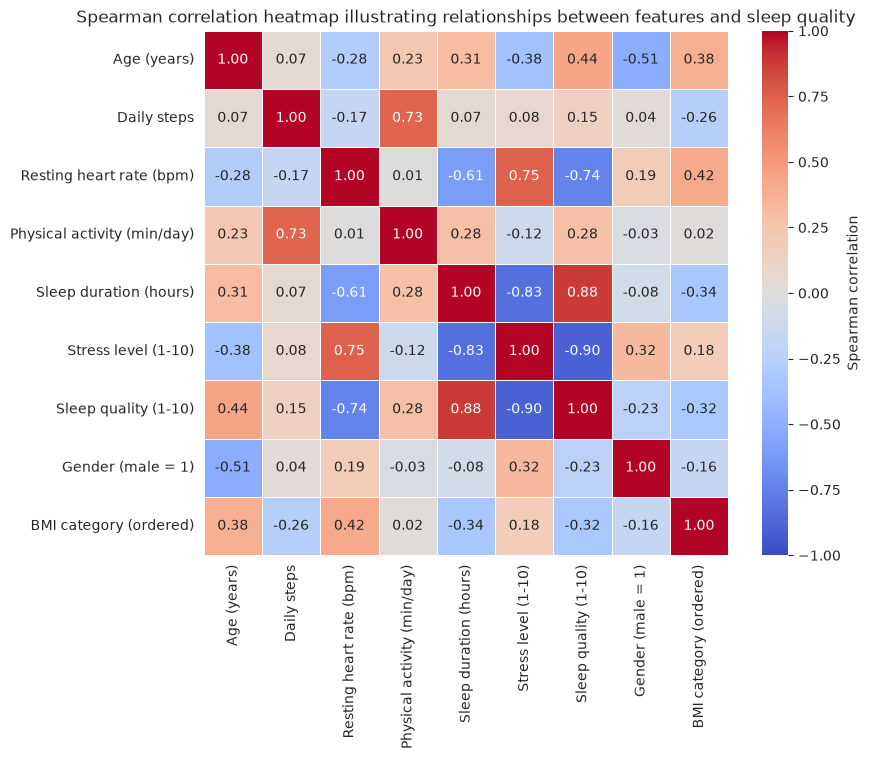

In [20]:
corr_data= df[num_cols + [TARGET]].copy()
corr_data["gender_male"]= (df["gender"]=="male").astype(int)
corr_data["bmi_order"]=df["bmi_category"].map({"underweight":0,"normal": 1,"overweight":2,"obese":3})

corr= corr_data.corr(method="spearman")
corr_display= corr.rename(index=labels, columns=labels)

plt.figure(figsize=(9,7.5))
sns.heatmap(corr_display, annot=True, fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1,cbar_kws={"label": "Spearman correlation"}, square=True, linewidths=0.5)
plt.title("Spearman correlation heatmap illustrating relationships between features and sleep quality")
plt.tight_layout()
plt.savefig(FIG + "/eda_05_correlation_heatmap.png")
plt.show()

In [21]:
print("Spearman correlation with sleep quality: ")
print(corr[TARGET].drop(TARGET).sort_values().round(2))

Spearman correlation with sleep quality: 
stress_level              -0.90
heart_rate                -0.74
bmi_order                 -0.32
gender_male               -0.23
daily_steps                0.15
physical_activity_level    0.28
age                        0.44
sleep_duration             0.88
Name: quality_of_sleep, dtype: float64


Spearman correlation between the features and the sleep-quality score (gender coded male = 1, BMI category ordered from underweight to obese). Stress level has the strongest link with sleep quality (negative), followed by heart rate (negative) and sleep duration (positive). Daily steps and physical activity are strongly related to each other (0.83).

6. Assessing Sleep Quality against every other feature

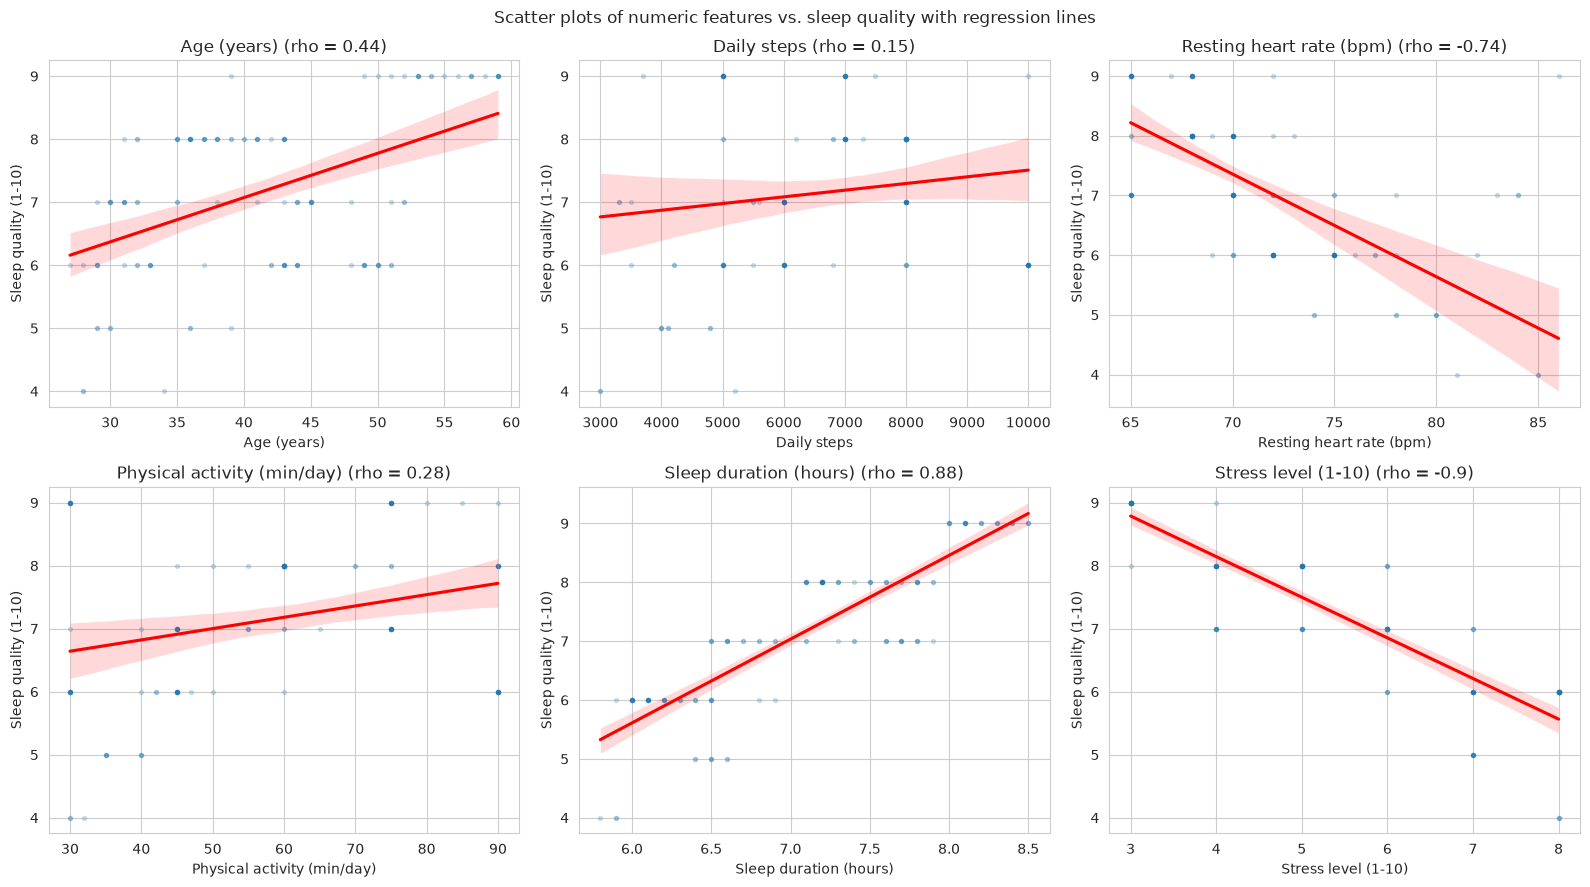

In [22]:
fig, axes = plt.subplots(2,3, figsize=(16,9))
axes=axes.flatten()
for i in range(6):
    col = num_cols[i] # Retrieves column name for the current iteration
    sns.regplot(x=col, y=TARGET, data=df, ax=axes[i], scatter_kws={"s":8,"alpha": 0.2}, line_kws={"color":"red"})
    # In seaborn, the parameter scatter_kws controls the size andtransparency of the scatter points while line_kws defines the color of the regression line
    r = round(df[col].corr(df[TARGET],method="spearman"),2)
    # r contains the Spearman correlation coefficient between the current column and the target variable, and the final value is rounded to two decimals places for better readability
    axes[i].set_title(labels[col] + " (rho = " + str(r) + ")")
    axes[i].set_xlabel(labels[col])
    axes[i].set_ylabel("Sleep quality (1-10)")
# suptitle() is used to set a title for the entire figure
plt.suptitle("Scatter plots of numeric features vs. sleep quality with regression lines")
plt.tight_layout()
plt.savefig(FIG + "/eda_06_scatterplots_regression.png")
plt.show()

Figure caption: Demonstrates sleep quality score against each numeric feature, with a fitted trend line visualized in red. Sleep quality evidently drops as stress levels and heart rate spike and similarly, is improved with more stable sleep. However, factors such as age, daily steps, and activity virtually show no correlation.

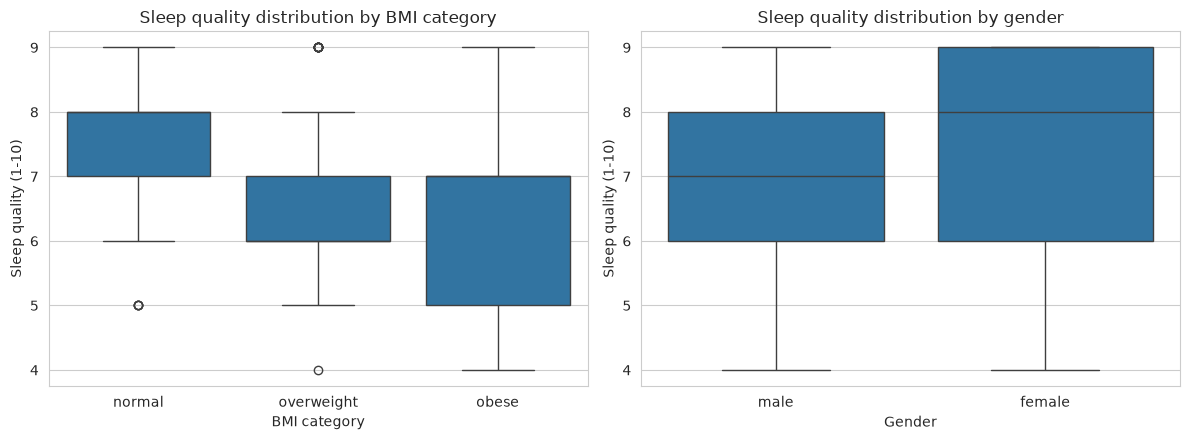

bmi_category
normal        7.51
obese         6.29
overweight    6.77
Name: quality_of_sleep, dtype: float64
gender
female    7.45
male      6.87
Name: quality_of_sleep, dtype: float64


In [23]:
fig, axes=plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x="bmi_category", y=TARGET, data=df, ax=axes[0], order=["normal", "overweight", "obese"])
axes[0].set_title("Sleep quality distribution by BMI category")
axes[0].set_xlabel("BMI category")
axes[0].set_ylabel("Sleep quality (1-10)")

sns.boxplot(x="gender", y=TARGET, data=df, ax=axes[1])
axes[1].set_title("Sleep quality distribution by gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Sleep quality (1-10)")

plt.tight_layout()
plt.savefig(FIG + "/eda_07_boxplots_categorical.png") # Save the figure to a file in the specified directory with the given filename
plt.show()

print(df.groupby("bmi_category")[TARGET].mean().round(2))
# Computes the mean sleep quality for each BMI category
print(df.groupby("gender")[TARGET].mean().round(2))
# Computes the mean sleep quality for each gender

Figure caption: The displayed boxplots demonstrate Sleep-quality score by BMI category and gender respectively. The groups yield similar medians, so neither feature separates sleep quality on its own **

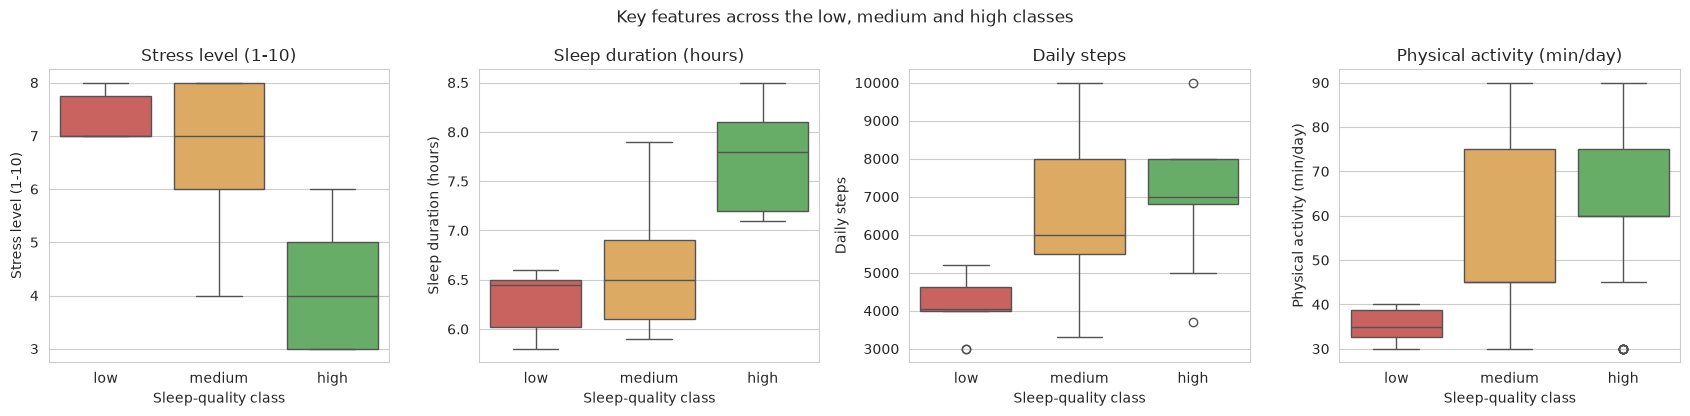

,age,daily_steps,heart_rate,physical_activity_level,sleep_duration,stress_level
sleep_quality_class,,,,,,
low,30.0,4050.0,80.0,35.0,6.4,7.0
medium,43.0,6000.0,72.0,45.0,6.5,7.0
high,41.0,7000.0,68.0,60.0,7.8,4.0


In [24]:
key_cols=["stress_level", "sleep_duration", "daily_steps", "physical_activity_level"]
fig, axes= plt.subplots(1,4, figsize=(17,4.2))
for i in range(4):
    sns.boxplot(x=CLASS, y=key_cols[i], data=df, ax=axes[i], order=class_order,
                hue=CLASS, hue_order=class_order, palette=class_colors, legend=False)
    axes[i].set_title(labels[key_cols[i]])
    axes[i].set_xlabel("Sleep-quality class")
    axes[i].set_ylabel(labels[key_cols[i]])
plt.suptitle("Key features across the low, medium and high classes")
plt.tight_layout()
plt.savefig(FIG + "/eda_08_features_by_class.png")
plt.show()
df.groupby(CLASS)[num_cols].median().loc[class_order].round(1)

Figure caption: The displayed box plots outputs stress level, sleep duration, physical activity and daily steps within each sleep-quality class. The median stress level falls from 6.8 (low) to 3.1 (high) and median sleep duration rises from 6.4 h to 7.5 h, while activity and steps illustrate a subtle, slight change.

Synthesis of figure findings

- 2091 records in total, with 8 input features, classes: low 21.6%, medium 51.6%, high 26.9%.
- Stress level feature is regarded as the strongest single factor that deteriorates sleep quality, as indicated by the Spearman's statistic (rho=-0.70), followed by increases heart rate (rho=-0.40), and sleep duration (rho=+0.32).
- Age, gender, BMI category, daily steps, and physical activity each have virtually no direct correlation with sleep quality - given that their |rho| yields a value less than 0.1.
- Daily steps and physical activity are highly correlated with an rho yielding a value of 0.83, implying that they carry redundant information.

## 3. Data Splitting and Model Preprocessing

### Train/Test Split

In [25]:
train_df, test_df = train_test_split(
    df[FEATURES + [TARGET, CLASS]],
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df[CLASS]
)

X_train = train_df[FEATURES]
X_test = test_df[FEATURES]

y_reg_train = train_df[TARGET]
y_reg_test = test_df[TARGET]

y_clf_train = train_df[CLASS]
y_clf_test = test_df[CLASS]

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (105, 8)
Testing set: (27, 8)


### Build Preprocessing Pipeline

In [26]:
def build_preprocessor():

    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            drop="if_binary",
            sparse_output=False
        ))
    ])

    return ColumnTransformer([
        ("num", numeric, NUM_FEATURES),
        ("cat", categorical, CAT_FEATURES)
    ])


def pipe(model):
    return Pipeline([
        ("prep", build_preprocessor()),
        ("model", model)
    ])

In [ ]:
# export and save train/test split
df.to_csv(f"{OUT}/dataset1_clean.csv", index=False)
train_df.to_csv(f"{OUT}/train.csv", index=False)
test_df.to_csv(f"{OUT}/test.csv", index=False)

## 4. Feature Analysis and Engineering

We examine the relationships between input features and sleep quality, identify important predictors, and explore additional features that may improve model performance.

1. Feature Corralation Analysis

2. Feature Engineering

3. Comparing Original VS Engineered Features

In [29]:
# we will work on copies to perserve original features for comparison
X_train_original = X_train.copy()
X_test_original = X_test.copy()

print("Training shape:", X_train_original.shape)
print("Testing shape:", X_test_original.shape)

Training shape: (105, 8)
Testing shape: (27, 8)


## 4.1 Feature Corralation Analysis

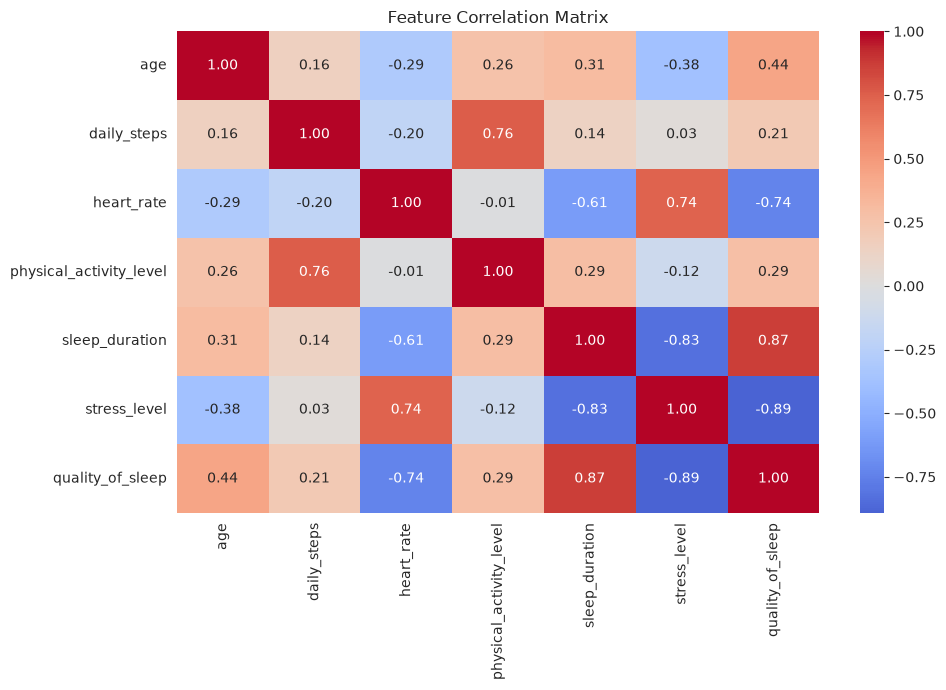

In [32]:
# Combine numerical training features with the regression target
corr_data = X_train_original.select_dtypes(include="number").copy()
corr_data[TARGET] = y_reg_train

# Calculate Spearman correlations
corr_matrix = corr_data.corr(method="spearman")

# Display correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(f"{FIG}/feature_analysis_correlation_heatmap.png", dpi=150)
plt.show()

#### Corralation Analysis/Findings
The heatmap shows that the two strongest relationships to sleep quality were stress level and sleep duration, with a respective corralation of -0.89 and 0.87, followed by heart rate at -0.74. This tells us that these features may be especially important for predicting sleep quality.

## 4.2 Feature Engineering
This section focuses on deriving new variables from our existing input features to see if it helps our models improve sleep quality prediction.

We will create the following four additional engineered features:

- **Stress-Sleep Interaction**: multiplies stress level by sleep duration
- **Stress-Heart Rate Interaction**: multiplies stress level by heart rate
- **Steps-per-Activity Level**: divides daily steps by physical activity level + 1
- **Sleep Deviation**: measures the absolute difference between sleep duration and the ideal 8 hours

Then, we will compare the models trained using the original 8 features VS models created using all 12 features

In [33]:
# Create engineered features
def create_features(X):
    X = X.copy()

    # Interaction between stress level and sleep duration
    X["stress_sleep_interaction"] = X["stress_level"] * X["sleep_duration"]

    # Interaction between stress level and heart rate
    X["stress_heart_interaction"] = X["stress_level"] * X["heart_rate"]

    # Daily steps relative to physical activity level
    X["steps_per_activity"] = X["daily_steps"] / (X["physical_activity_level"] + 1)

    # Deviation from 8 hours of sleep
    X["sleep_deviation"] = abs(X["sleep_duration"] - 8)

    return X


# Apply feature engineering to training and testing data
X_train_engineered = create_features(X_train_original)
X_test_engineered = create_features(X_test_original)

# Display engineered features
new_features = [
    "stress_sleep_interaction",
    "stress_heart_interaction",
    "steps_per_activity",
    "sleep_deviation"
]

print('New shapes:',X_train_engineered.shape, X_test_engineered.shape)
display(X_train_engineered[new_features].head())

New shapes: (105, 12) (27, 12)


,stress_sleep_interaction,stress_heart_interaction,steps_per_activity,sleep_deviation
46,28.8,272,114.754098,0.8
76,44.8,504,130.434783,1.6
66,43.8,432,87.323944,0.7
58,36.0,340,131.147541,0.8
29,48.0,576,161.290323,2.0


In [34]:
# Create a pipeline that includes engineered features
def engineered_pipe(model):
    preprocessor = build_preprocessor()

    # Add engineered features to the numerical preprocessing
    preprocessor.transformers[0] = (
        "num",
        preprocessor.transformers[0][1],
        NUM_FEATURES + new_features
    )

    return Pipeline([
        ("prep", preprocessor),
        ("model", model)
    ])

## 4.3 Comparing Original VS Engineered Features

### Linear Regression

In [ ]:

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Compare original and engineered features
results = []

for name, model, X in [
    ("Original", pipe(LinearRegression()), X_train_original),
    ("Engineered", engineered_pipe(LinearRegression()), X_train_engineered)
]:
    scores = cross_validate(
        model,
        X,
        y_reg_train,
        cv=cv,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error"
        }
    )

    results.append({
        "Features": name,
        "CV R²": scores["test_r2"].mean(),
        "CV MAE": -scores["test_mae"].mean()
    })

# Create a comparison table
linear_comparison = pd.DataFrame(results)
original = linear_comparison.iloc[0]
engineered = linear_comparison.iloc[1]

comparison_table = pd.DataFrame({
    "Metric": ["CV R²", "CV MAE"],
    "Original": [original["CV R²"], original["CV MAE"]],
    "Engineered": [engineered["CV R²"], engineered["CV MAE"]],
    "Change": [
        engineered["CV R²"] - original["CV R²"],
        engineered["CV MAE"] - original["CV MAE"]
    ]
})

# display and save results
display(comparison_table.round(4).set_index("Metric"))

comparison_table.to_csv(f"{RES}/feature_engineering_linear_comparison.csv")

,Original,Engineered,Change
Metric,,,
CV R²,0.8804,0.8960,0.0156
CV MAE,0.3111,0.2665,-0.0447


#### **Linear Regression Feature Engineering Findings**

Both changes indicate improvement for Linear Regression with the engineered features. 

The mean CV R² slightly increased from 0.8804 to 0.8960, while MAE significantly decreased from 0.3111 to 0.2665 (14.35% reduction). 

### Logistic Regression

In [40]:

cv_clf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Compare original and engineered features
results_clf = []

for name, model, X in [
    ("Original", pipe(LogisticRegression(max_iter=1000)), X_train_original),
    ("Engineered", engineered_pipe(LogisticRegression(max_iter=1000)), X_train_engineered)
]:
    scores = cross_validate(
        model,
        X,
        y_clf_train,
        cv=cv_clf,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1_macro"
        }
    )

    results_clf.append({
        "Features": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Macro F1": scores["test_f1"].mean()
    })

# Create a comparison table
logistic_comparison = pd.DataFrame(results_clf)

original = logistic_comparison.iloc[0]
engineered = logistic_comparison.iloc[1]

logistic_table = pd.DataFrame({
    "Metric": ["CV Accuracy", "CV Macro F1"],
    "Original": [original["CV Accuracy"], original["CV Macro F1"]],
    "Engineered": [engineered["CV Accuracy"], engineered["CV Macro F1"]],
    "Change": [
        engineered["CV Accuracy"] - original["CV Accuracy"],
        engineered["CV Macro F1"] - original["CV Macro F1"]
    ]
})

# Display and save results
logistic_table = logistic_table.round(4).set_index("Metric")

display(logistic_table)

logistic_table.to_csv(f"{RES}/feature_engineering_logistic_comparison.csv")

,Original,Engineered,Change
Metric,,,
CV Accuracy,0.9143,0.9143,0.0
CV Macro F1,0.8639,0.8639,0.0


#### **Linear Regression Feature Engineering Findings**
There was no change to CV accuracy or macro F1-score, which means Logistic regression showed no improvement in classification with the added features, unlike Linear Regression.

## 5. Building and Evaluating Regression and Classification Models

### 5.1 Linear Regression Evalutation  

In [51]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

# Define regression models using engineered features
reg_models = {
    "Mean Predictor": engineered_pipe(DummyRegressor(strategy="mean")),
    "Linear Regression": engineered_pipe(LinearRegression())
}

reg_rows = []

for name, model in reg_models.items():
    scores = cross_validate(
        model,
        X_train_engineered,
        y_reg_train,
        cv=kf,
        scoring=scoring
    )

    reg_rows.append({
        "model": name,
        "cv_r2": scores["test_r2"].mean(),
        "cv_mae": -scores["test_mae"].mean(),
        "cv_rmse": -scores["test_rmse"].mean()
    })

# Tune Ridge Regression
ridge_grid = GridSearchCV(
    engineered_pipe(Ridge()),
    {"model__alpha": [0.01, 0.1, 1, 10, 30, 100]},
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="r2"
)

ridge_grid.fit(X_train_engineered, y_reg_train)
best_ridge = ridge_grid.best_estimator_

print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"])

scores = cross_validate(
    ridge_grid,
    X_train_engineered,
    y_reg_train,
    cv=kf,
    scoring=scoring
)

reg_rows.append({
    "model": "Ridge Regression",
    "cv_r2": scores["test_r2"].mean(),
    "cv_mae": -scores["test_mae"].mean(),
    "cv_rmse": -scores["test_rmse"].mean()
})


reg_cv = pd.DataFrame(reg_rows)

display(reg_cv.round(4).set_index("model"))

reg_cv.to_csv(f"{RES}/regression_cv_results.csv", index=False)

Best Ridge alpha: 0.01


,cv_r2,cv_mae,cv_rmse
model,,,
Mean Predictor,-0.0425,1.0612,1.2508
Linear Regression,0.8960,0.2665,0.3724
Ridge Regression,0.8855,0.2876,0.3893


### 5.2 Classification Evalutation 

In [50]:
skf = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

clf_models = {
    "Majority Class": pipe(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": pipe(LogisticRegression(max_iter=2000))
}

clf_scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro"
}

clf_rows = []

for name, model in clf_models.items():
    scores = cross_validate(
        model, X_train, y_clf_train,
        cv=skf, scoring=clf_scoring
    )

    clf_rows.append({
        "model": name,
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_f1_macro": scores["test_f1_macro"].mean()
    })

# Tune Logistic Regression
logit_grid = GridSearchCV(
    pipe(LogisticRegression(max_iter=2000)),
    {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },
    cv=skf,
    scoring="f1_macro"
)

logit_grid.fit(X_train, y_clf_train)
best_logit = logit_grid.best_estimator_

print("Best Logistic Regression parameters:", logit_grid.best_params_)

scores = cross_validate(
    best_logit, X_train, y_clf_train,
    cv=skf, scoring=clf_scoring
)

clf_rows.append({
    "model": "Tuned Logistic Regression",
    "cv_accuracy": scores["test_accuracy"].mean(),
    "cv_f1_macro": scores["test_f1_macro"].mean()
})

clf_cv = pd.DataFrame(clf_rows)

display(clf_cv.round(4).set_index("model"))

clf_cv.to_csv(f"{RES}/classification_cv_results.csv", index=False)

Best Logistic Regression parameters: {'model__C': 10, 'model__class_weight': None}


,cv_accuracy,cv_f1_macro
model,,
Majority Class,0.4952,0.2207
Logistic Regression,0.9143,0.8639
Tuned Logistic Regression,0.9333,0.9231


## 6. Building and Evaluating Random Forest Regression and Classification Models

### 6.1 Random Forest Regressor